# Solving Inverse Problem using Connectome Spectrum Electromagnetic Tomography (CSET)

In this section we will solve the inverse problem using our new method CSET. This requires the eeg measurements, the forward solution and the connectome spectrum transform (prior). <br>
The method solves the following problem: $$\vec{x}^* = \text{argmin}_{\vec{x}} \lVert A\vec{x}-b \rVert_2^2 + \lambda \lVert F\vec{x}\rVert_1$$
where
- $\vec{x}^* \in \mathbb{R}^n$ is the reconstructed brain activity.
- $\vec{x} \in \mathbb{R}^n$ is the brain activity.
- $\vec{b} \in \mathbb{R}^m$ are the eeg measurements.
- $A \in \mathbb{R}^{m\times n}$ is the forward matrix.
- $F \in \mathbb{R}^{n \times n}$ is the connectome spectrum transform.
- $\lambda \in \mathbb{R}$ is the regularizer parameter.

Regularizing with $\lVert F\vec{x} \rVert_1$ imposes the connectome spectrum of $\vec{x}$ to be sparse and $\lambda$ 

## 📦 Imports

In [11]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path
import pyvista as pv

import pyxu.abc as pxa
import pyxu.operator as pxo 
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

In [2]:
# configuration
sub    = "vepcon_sub-10"
config = mm.io.read_config("../configurations/simf.yml")
sample = "sample2"

# data
data = mm.io.read_dataset(sub, "fwd", "cst", sample)

# features
fwd = mne.convert_forward_solution(data["fwd"], force_fixed=True, verbose="warning")
fwd = fwd["sol"]["data"].astype("float64")                                              # forward matrix

data["gt"]  = data[sample][0]
data["eeg_inv"] = data[sample][1]

#### 🌟 Visualize ground truth

In [3]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=200)

Widget(value='<iframe src="http://localhost:38165/index.html?ui=P_0x720ceaf43560_0&reconnect=auto" class="pyvi…

#### 🌟 Visualize EEG time series

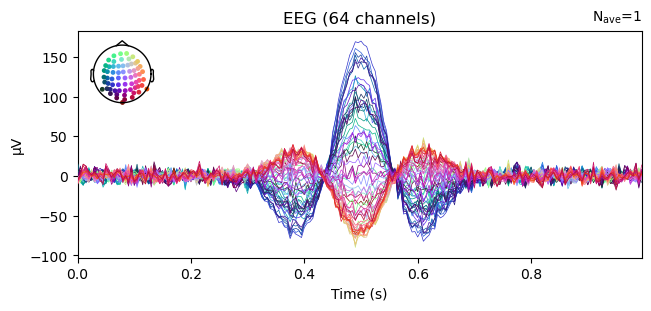

In [4]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

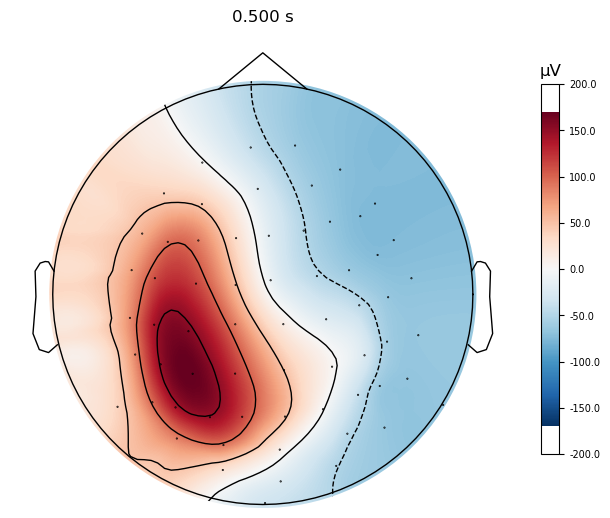

In [5]:
times = [0.5]
_ = data["eeg_inv"].plot_topomap(times=times, size=4)

#### 🌟 Visualize forward matrix

In [6]:
mm.viz.plot_leadfield(data["eeg_inv"], data["fwd"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:38165/index.html?ui=P_0x720ca216f500_2&reconnect=auto" class="pyvi…

#### 🌟 Visualize connectome spectrum transform

In [7]:
signal = data["cst"][1]
max_abs = max(abs(signal.max()), abs(signal.min()))
clim    = [-max_abs, max_abs]
mm.viz.plot_brain_signal(data["fwd"]["src"], signal, clim=clim).show()

Widget(value='<iframe src="http://localhost:38165/index.html?ui=P_0x720ca2144440_3&reconnect=auto" class="pyvi…

🛠️ <font color=violet>**Select time points to reconstruct**</font>: CSET is an iterative process. This can be quite slow, so let's restrain the number of time points we reconstruct.

Number of time points: (64, 4)


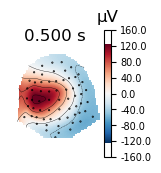

In [8]:
tmin  = 0.49
tmax  = 0.51
tviz  = 0.5
sfreq = data["eeg_inv"].info["sfreq"]

b = data["eeg_inv"].get_data("eeg", tmin=tmin, tmax=tmax)

print(f"Number of time points: {b.shape}")
_ = data["eeg_inv"].plot_topomap([tviz], outlines=None, extrapolate="local")

## Solve The Inverse Problem

🛠️ <font color=violet>**Select CSET parameters**</font>: Select the regularizer parameter $\lambda$

In [8]:
lam = 0.01

⚙️ <font color=green>**Write the optimization problem**</font>: Using the `pyxu` package we can write down any optimization problem and then solve them.

In [9]:
# forward * connectome spectrum
A = fwd @ data["cst"].T
A = pxa.LinOp.from_array(A)

# L1 norm
l1_norm = lam*pxo.L1Norm(dim_shape=A.dim_shape)

# initial guess
alpha0 = np.random.random(A.dim_shape)*10**(-9)
#alpha0 = np.zeros(A.dim_shape)

# stopping criterion (number of iteration only)
sc = pxst.MaxIter(1000)

##########################
### Solve 1 time point ###
##########################
b, t = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
b    = b/np.linalg.norm(b)
print(f"50% rising phase: {t/data["eeg_inv"].info["sfreq"]:03} [s]")

l22_loss = pxo.SquaredL2Norm(dim_shape=A.codim_shape).argshift(-b)*A
l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()

solver = PGD(f=l22_loss, g=l1_norm)

solver.fit(x0=alpha0, stop_crit=sc)

alpha = solver.solution().squeeze()
recon = data["cst"].T @ alpha

50% rising phase: 0.46 [s]
INFO -- [2024-11-27 15:42:01.002150] Iteration 0
	iteration: 0
	N_iter: 1
INFO -- [2024-11-27 15:42:01.003473] Iteration 1
	iteration: 1
	N_iter: 2
INFO -- [2024-11-27 15:42:01.004166] Iteration 2
	iteration: 2
	N_iter: 3
INFO -- [2024-11-27 15:42:01.004763] Iteration 3
	iteration: 3
	N_iter: 4
INFO -- [2024-11-27 15:42:01.005531] Iteration 4
	iteration: 4
	N_iter: 5
INFO -- [2024-11-27 15:42:01.006121] Iteration 5
	iteration: 5
	N_iter: 6
INFO -- [2024-11-27 15:42:01.006694] Iteration 6
	iteration: 6
	N_iter: 7
INFO -- [2024-11-27 15:42:01.007261] Iteration 7
	iteration: 7
	N_iter: 8
INFO -- [2024-11-27 15:42:01.007815] Iteration 8
	iteration: 8
	N_iter: 9
INFO -- [2024-11-27 15:42:01.008324] Iteration 9
	iteration: 9
	N_iter: 10
INFO -- [2024-11-27 15:42:01.008871] Iteration 10
	iteration: 10
	N_iter: 11
INFO -- [2024-11-27 15:42:01.009409] Iteration 11
	iteration: 11
	N_iter: 12
INFO -- [2024-11-27 15:42:01.009911] Iteration 12
	iteration: 12
	N_iter: 13
I

#### <font color=yellow>🌟</font> Visualize reconstruction

In [13]:
clim    = [0, np.max(np.abs(recon))] 
mm.viz.plot_brain_signal(data["fwd"]["src"], np.abs(recon), cmap="reds", clim=clim).show()

Widget(value='<iframe src="http://localhost:38165/index.html?ui=P_0x720ca03c8f20_6&reconnect=auto" class="pyvi…

## 💾 Save result

In [9]:
save = "mne"
#save = "bv"

fname  = f"{sub}_cset-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation of subject: {sub}")
if save == "mne":
    vertices = [forward["src"][0]["vertno"], forward["src"][1]["vertno"]]
    stc = mne.SourceEstimate(solution, vertices, tmin=0, tstep=1/sfreq, subject=sub)
    stc.save(folder/fname, overwrite=True)
    
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )

Writing STC to disk...
[done]


#### Pyxu debug

Widget(value='<iframe src="http://localhost:37369/index.html?ui=P_0x75a4cc115520_8&reconnect=auto" class="pyvi…

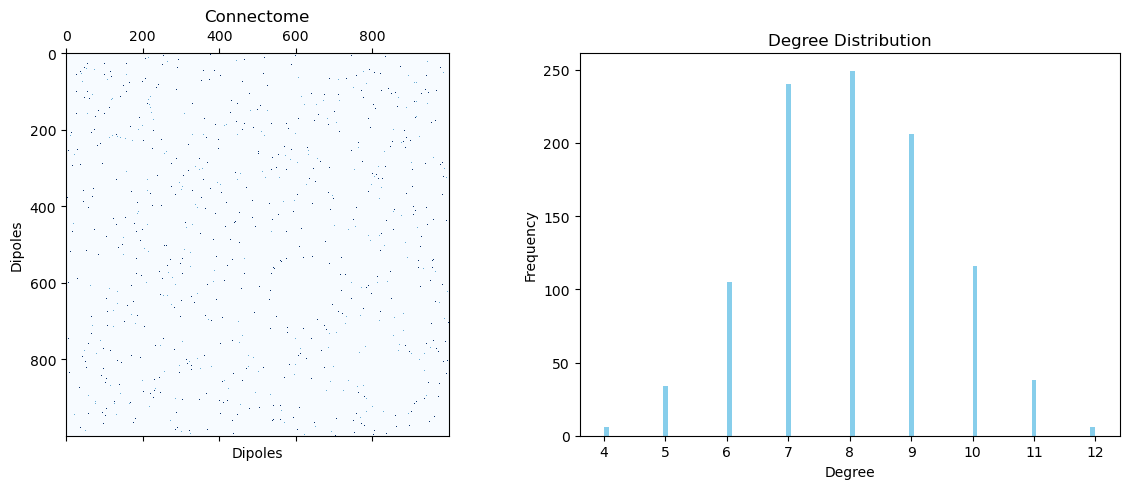

In [20]:
# generate connections
tree = sp.spatial.KDTree(sources)
dd, ii = tree.query(sources, k=5)

conn = np.zeros((len(sources), len(sources)))
for i in range(len(sources)):
    conn[i, ii[i]] = 1
conn = conn - np.eye(len(sources))
conn = conn + conn.T

mm.viz.plot_connectome(conn)

(100, 1000)

In [47]:
# generate signals
G = pygsp.graphs.Graph(conn, lap_type="normalized", coords=sources)
G.compute_fourier_basis()
cst = G.U.T

alpha = np.zeros(len(sources))
alpha[[1,3,5,10]] = 1

print(f"Sparsity: {(1-np.sum(alpha>0)/len(alpha))*100:.3}%")

# source signal
signal1 = cst.T @ alpha
src["sources"] = signal1

# sensor signal
signal2 = forward @ signal1
sen["sensors"] = signal2

p = pv.Plotter()
p.add_mesh(src, render_points_as_spheres=True, point_size=10)
p.add_mesh(sen, point_size=8)
p.show()

Sparsity: 99.6%


Widget(value='<iframe src="http://localhost:37369/index.html?ui=P_0x75a4b48904d0_16&reconnect=auto" class="pyv…

In [48]:
# regularizer parameter
lam = 0.1

# forward * connectome spectrum
A = forward @ cst.T
#A = A / np.linalg.norm(A, axis=0)[None,:]
A = pxa.LinOp.from_array(A)

# L1 norm
l1_norm = lam*pxo.L1Norm(dim_shape=A.dim_shape)

# initial guess
alpha0 = np.zeros(A.dim_shape)
#alpha0 = np.random.random(A.dim_shape)*10**(-2)

# stopping criterion (number of iteration only)
sc = pxst.MaxIter(1000)

b = signal2*1e-9
b = b/np.linalg.norm(b)

l22_loss = pxo.SquaredL2Norm(dim_shape=A.codim_shape).argshift(-b)*A
l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()

solver = PGD(f=l22_loss, g=lam*l1_norm)
alpha
solver.fit(x0=alpha0, stop_crit=sc)

recon_alpha = solver.solution().squeeze()
recon = cst.T @ recon_alpha

INFO -- [2024-11-27 11:36:21.184915] Iteration 0
	iteration: 0
	N_iter: 1
INFO -- [2024-11-27 11:36:21.188225] Iteration 1
	iteration: 1
	N_iter: 2


INFO -- [2024-11-27 11:36:21.188776] Iteration 2
	iteration: 2
	N_iter: 3
INFO -- [2024-11-27 11:36:21.189457] Iteration 3
	iteration: 3
	N_iter: 4
INFO -- [2024-11-27 11:36:21.189898] Iteration 4
	iteration: 4
	N_iter: 5
INFO -- [2024-11-27 11:36:21.190445] Iteration 5
	iteration: 5
	N_iter: 6
INFO -- [2024-11-27 11:36:21.190954] Iteration 6
	iteration: 6
	N_iter: 7
INFO -- [2024-11-27 11:36:21.191373] Iteration 7
	iteration: 7
	N_iter: 8
INFO -- [2024-11-27 11:36:21.191836] Iteration 8
	iteration: 8
	N_iter: 9
INFO -- [2024-11-27 11:36:21.192663] Iteration 9
	iteration: 9
	N_iter: 10
INFO -- [2024-11-27 11:36:21.193047] Iteration 10
	iteration: 10
	N_iter: 11
INFO -- [2024-11-27 11:36:21.193410] Iteration 11
	iteration: 11
	N_iter: 12
INFO -- [2024-11-27 11:36:21.194123] Iteration 12
	iteration: 12
	N_iter: 13
INFO -- [2024-11-27 11:36:21.194500] Iteration 13
	iteration: 13
	N_iter: 14
INFO -- [2024-11-27 11:36:21.195178] Iteration 14
	iteration: 14
	N_iter: 15
INFO -- [2024-11-27 11

In [49]:
src["recon"] = recon

p = pv.Plotter()
p.add_mesh(src, render_points_as_spheres=True, scalars="recon", point_size=10)
p.add_mesh(sen, point_size=8)
p.show()

Widget(value='<iframe src="http://localhost:37369/index.html?ui=P_0x75a4b4698230_17&reconnect=auto" class="pyv…

<Axes: >

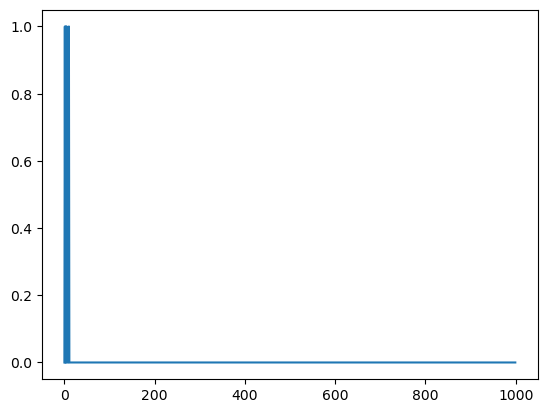

In [50]:
import seaborn as sns 
sns.lineplot(alpha)

<Axes: >

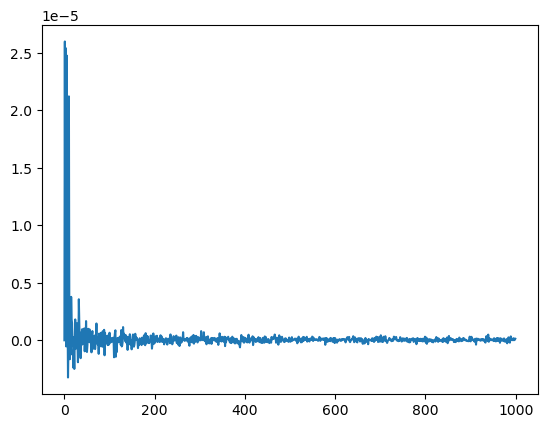

In [51]:
sns.lineplot(recon_alpha)